# 01 — Q1: Which cell types express each program, and which produce each chemokine?

Two different questions hide inside "which cell type has the highest expression":

| view | definition | answers |
|---|---|---|
| **per-cell level** | mean log2(CPM + 1) of the program's genes in the cell type's pseudobulk | which cells express it most, *per cell* |
| **contribution** | the cell type's share of all of the sample's transcripts for those genes | who produces most of it *in the tumour* — abundance × expression |

Both are computed per sample, then averaged within each condition (arm × site); the ranking is
then **bootstrapped over mice** so a "top cell type" is reported with how often it stays top.
A cell type enters a condition's ranking only with >= 2 usable samples (>= 10 cells each), so
one sparse sample of CD4 or Treg cannot top a ranking by noise.

Then the trap `rtAdvantage/03` hit: tumour-cell MHC signal that is mostly macrophage-dominant
genes. §4 estimates, per sample and per compartment, how much of each gene's signal is
**ambient macrophage RNA**, from macrophage-exclusive markers (`C1qa/b/c`, `Ms4a7`, `Adgre1`,
`Csf1r`) that a tumour cell, T cell or NK cell should not transcribe.

§5-6 do the same for chemokines and add the **expression vs abundance decomposition**: when a
cell type's share of a chemokine pool changes with treatment, is that more cells, or the same
cells making more? Only the second is a change in cell state.

## 1. Config and cache

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats

pd.set_option("display.width", 280); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 400)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/mhc_cytotox"; FIG = OUT/"figures"
assert (OUT/"pseudobulk_counts.parquet").exists(), "run 00 first"

SITE = {1: "Tu1", 2: "Tu2"}
ARM_ORDER = ["NoTx", "CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
CONDS = [f"{a}_Tu{s}" for a in ARM_ORDER for s in (1, 2)]
MIN_CELLS, N_BOOT, SEED = 10, 1000, 0
rng = np.random.default_rng(SEED)

PB = pd.read_parquet(OUT/"pseudobulk_counts.parquet")
PBM = pd.read_csv(OUT/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
PBM["cond"] = PBM.arm + "_Tu" + PBM.site.astype(str)
CAT = json.load(open(OUT/"programs.json")); PROGRAMS, AXES = CAT["programs"], CAT["axes"]
CPM = PB.div(PB.sum(1), axis=0) * 1e6
L = np.log2(CPM + 1)

LVL2 = ["Cancer_cell", "M1_like_Mac", "M2_like_Mac", "Intermediate_Mac", "Classical_Mono",
        "Nonclassical_Mono", "N1_like_Neu", "N2_like_Neu", "cDC", "pDC", "CD8_T", "NK", "NKT",
        "CD4_T", "Treg", "B", "Fibroblast", "Endothelial"]
LVL3 = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Mmp12_high_Mac",
        "MHCII_high_DC", "Cytotoxic_NK", "Granzyme_high_NK", "Proliferating_CD8_T",
        "SPP1_TAM", "cytotoxic_lymph"]
HEAD = ["MHC_I_machinery", "MHC_II_core", "IFNG_Hallmark", "ISG_core", "cyto_effector",
        "cyto_effector_noCcl5", "R01_granzyme_GO", "exh_inhibitory_receptors", "exh_TFs",
        "exh_progenitor", "exh_progenitor_noXcl1", "exh_terminal", "checkpoint_ligands"]
HEAD += [f"{a}_{r}" for a in AXES for r in ("ligands", "receptors")]
print(f"{len(PB)} pseudobulks | {len(HEAD)} headline programs")

1158 pseudobulks | 29 headline programs


## 2. Per-cell level, per condition, with a mouse-bootstrap ranking

In [2]:
def program_level(prog):
    gl = [g for g in PROGRAMS[prog]["genes"] if g in L.columns]
    return L[gl].mean(1) if gl else pd.Series(np.nan, index=L.index)


usable = PBM.n_cells >= MIN_CELLS
LEV = pd.DataFrame({p_: program_level(p_) for p_ in HEAD})
LEV = LEV.join(PBM[["group", "sample", "cond", "n_cells"]])
LEV = LEV[usable.values]
LEV.to_csv(OUT/"q1_program_level_per_sample.csv")

rows, top_rows = [], []
for prog in HEAD:
    for cond in CONDS:
        d = LEV[(LEV.cond == cond) & LEV.group.isin(LVL2 + LVL3)]
        if d.empty: continue
        means = d.groupby("group")[prog].mean()
        for g_, v in means.items():
            rows.append(dict(program=prog, cond=cond, group=g_, level=v,
                             n_samples=int((d.group == g_).sum())))
        # bootstrap over samples (= mice) of this condition, lvl2 partition only
        d2 = d[d.group.isin(LVL2)]
        P = d2.pivot_table(index="sample", columns="group", values=prog)      # samples x types
        P = P.loc[:, P.notna().sum() >= 2]          # a type needs >= 2 usable mice to be ranked
        if len(P) < 2 or P.shape[1] < 3: continue
        idx = rng.integers(0, len(P), (N_BOOT, len(P)))                        # resample mice
        with np.errstate(all="ignore"):
            BM = np.nanmean(P.values[idx], axis=1)                             # N_BOOT x types
        BM = np.where(np.isnan(BM), -np.inf, BM)
        order = np.argsort(-BM, axis=1)[:, :3]
        names = np.asarray(P.columns)
        top1 = pd.Series(names[order[:, 0]]).value_counts(normalize=True)
        top3 = pd.Series(names[order].ravel()).value_counts() / N_BOOT
        obs_rank = P.mean().sort_values(ascending=False)
        top_rows.append(dict(program=prog, cond=cond, top1=obs_rank.index[0],
                             top1_boot=float(top1.get(obs_rank.index[0], 0)),
                             top2=obs_rank.index[1], top3=obs_rank.index[2],
                             in_top3_boot=", ".join(f"{k} {v:.0%}" for k, v in top3.head(4).items())))
Q1 = pd.DataFrame(rows); TOP = pd.DataFrame(top_rows)
Q1.to_csv(OUT/"q1_level_by_condition.csv", index=False); TOP.to_csv(OUT/"q1_top_celltypes.csv", index=False)

print("TOP CELL TYPE per program x condition (per-cell level; bootstrap = % of mouse resamples "
      "it stays #1)")
w = TOP.assign(cell=lambda d: d.top1 + " (" + (100*d.top1_boot).round(0).astype(int).astype(str) + "%)")
print(w.pivot(index="program", columns="cond", values="cell").reindex(HEAD)[[c for c in CONDS if c in set(TOP.cond)]]
       .to_string())

TOP CELL TYPE per program x condition (per-cell level; bootstrap = % of mouse resamples it stays #1)
cond                                      NoTx_Tu1                 NoTx_Tu2               CyPSCA_Tu1               CyPSCA_Tu2                CyT72_Tu1                CyT72_Tu2             RTCyPSCA_Tu1             RTCyPSCA_Tu2              RTCyT72_Tu1              RTCyT72_Tu2
program                                                                                                                                                                                                                                                                            
MHC_I_machinery                         cDC (100%)               cDC (100%)        M1_like_Mac (47%)        M1_like_Mac (97%)              CD8_T (75%)               cDC (100%)        Endothelial (57%)        Endothelial (57%)              CD8_T (96%)               cDC (100%)
MHC_II_core                 Intermediate_Mac (96%)  Intermediate_Mac (1


per-cell level (mean log2 CPM+1 of program genes), treated samples pooled
group                     Cancer_cell  M1_like_Mac  M2_like_Mac  Intermediate_Mac  Classical_Mono  Nonclassical_Mono  N1_like_Neu  N2_like_Neu    cDC   pDC  CD8_T    NK   NKT  CD4_T  Fibroblast  Endothelial  IFN_stimulated_Mac  Apoe_high_Mac  Arg1_high_Mac  Fn1_high_Mac  Mmp12_high_Mac  MHCII_high_DC  Cytotoxic_NK  Granzyme_high_NK  Proliferating_CD8_T  SPP1_TAM  cytotoxic_lymph
MHC_I_machinery                  5.11         8.30         8.03              7.91            8.24               7.74         7.56         5.73   8.34  7.92   8.20  7.71  8.46   8.05        6.20         8.15                8.30           8.11           7.95          7.84            7.91           8.20          7.81              7.44                 8.32      8.07             7.91
MHC_II_core                      5.56        10.26         8.63             10.56            7.75               8.49         4.33         4.61   8.01  7.12   3.0

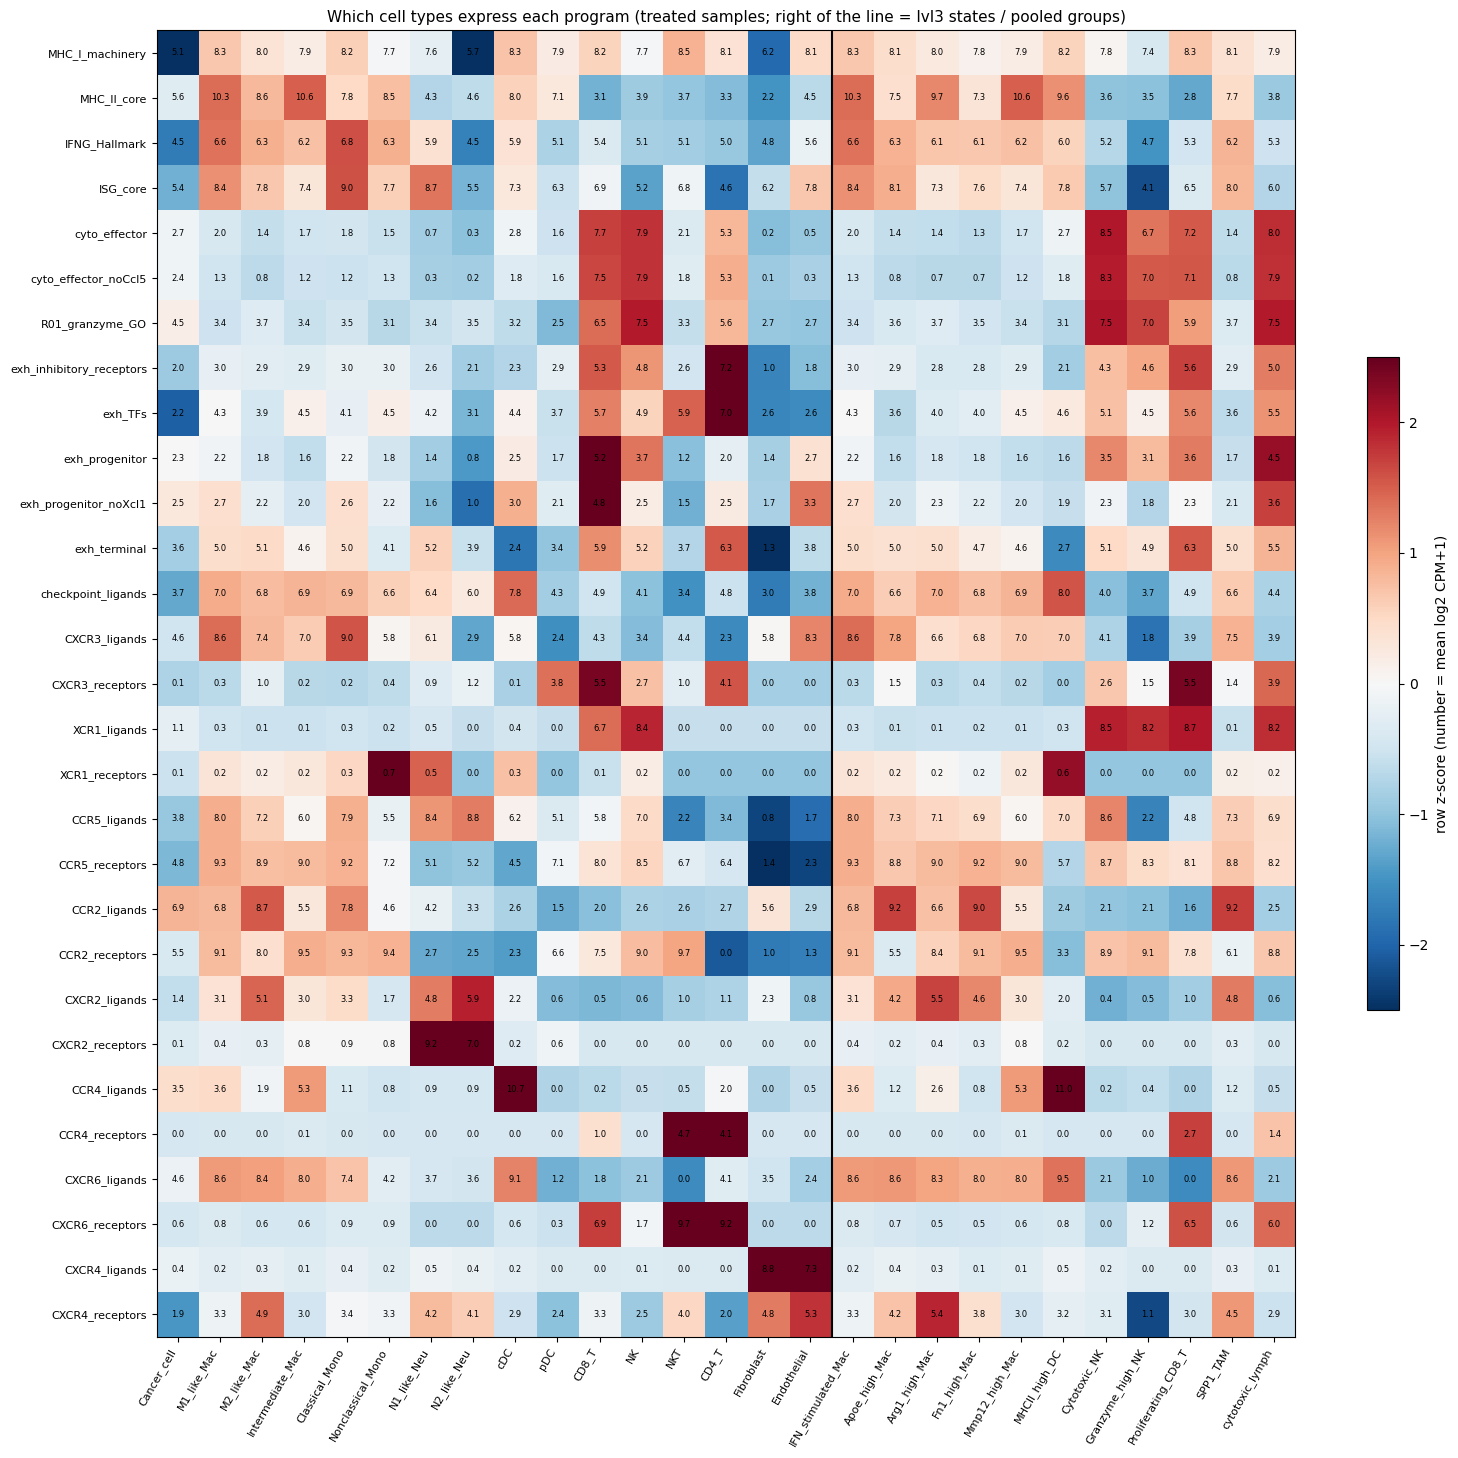

In [3]:
# the per-cell level of the headline programs across lvl2 types — treated samples pooled
tr = LEV[~LEV.cond.str.startswith("NoTx") & LEV.group.isin(LVL2 + LVL3)]
H = tr.groupby("group")[HEAD].mean().reindex([g for g in LVL2 + LVL3 if g in set(tr.group)])
print("\nper-cell level (mean log2 CPM+1 of program genes), treated samples pooled")
print(H.T.round(2).to_string())

fig, ax = plt.subplots(figsize=(16, 0.42*len(HEAD) + 2.5))
Z = (H.T - H.T.mean(1).values[:, None]) / H.T.std(1).values[:, None]
im = ax.imshow(Z.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -2.5, 2.5), aspect="auto")
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        ax.text(j, i, f"{H.T.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
ax.set_xticks(range(Z.shape[1])); ax.set_xticklabels(Z.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(Z.shape[0])); ax.set_yticklabels(Z.index, fontsize=8)
ax.axvline(len([g for g in LVL2 if g in H.index]) - 0.5, color="k", lw=1.5)
plt.colorbar(im, ax=ax, shrink=.5, label="row z-score (number = mean log2 CPM+1)")
ax.set_title("Which cell types express each program (treated samples; right of the line = lvl3 "
             "states / pooled groups)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"01_program_by_celltype.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Contribution — who produces the program's transcripts in the tumour?

Over the **lvl2 partition** only (every cell counted once): a cell type's share of the summed
raw counts of the program's genes in its sample. This folds in abundance, so a rare cell type
with a very high per-cell level can contribute little, and a common one with a modest level a
lot.

In [4]:
part = PBM[PBM.group.isin(LVL2)]
CONTRIB = []
for prog in HEAD:
    gl = [g for g in PROGRAMS[prog]["genes"] if g in PB.columns]
    tot = PB.loc[part.index, gl].sum(1)
    d = part[["group", "sample", "cond"]].assign(umi=tot.values)
    d["share"] = d.umi / d.groupby("sample").umi.transform("sum")
    CONTRIB.append(d.assign(program=prog))
CONTRIB = pd.concat(CONTRIB)
CS = CONTRIB.groupby(["program", "cond", "group"]).share.mean().reset_index()
CS.to_csv(OUT/"q1_contribution_by_condition.csv", index=False)
cs_tr = (CONTRIB[~CONTRIB.cond.str.startswith("NoTx")].groupby(["program", "group"]).share.mean()
         .unstack().reindex(HEAD))
print("share of each program's transcripts, treated samples pooled (rows sum to 1)")
print((cs_tr*100).round(1)[[g for g in LVL2 if g in cs_tr]].to_string())

top_c = (CS.dropna(subset=["share"]).sort_values("share", ascending=False).groupby(["program", "cond"]).head(1)
           .assign(cell=lambda d: d.group + " " + (100*d.share).round(0).astype(int).astype(str) + "%")
           .pivot(index="program", columns="cond", values="cell").reindex(HEAD))
print("\nLARGEST CONTRIBUTOR per program x condition")
print(top_c[[c for c in CONDS if c in top_c]].to_string())

share of each program's transcripts, treated samples pooled (rows sum to 1)
group                     Cancer_cell  M1_like_Mac  M2_like_Mac  Intermediate_Mac  Classical_Mono  Nonclassical_Mono  N1_like_Neu  N2_like_Neu   cDC  pDC  CD8_T    NK   NKT  CD4_T  Treg    B  Fibroblast  Endothelial
program                                                                                                                                                                                                                
MHC_I_machinery                   0.3         20.9         36.0              10.3            24.8                3.3          0.4          0.1   1.6  0.2    0.4   0.9   0.1    0.1   0.1  0.0         0.2          0.3
MHC_II_core                       0.1         37.1         20.7              30.1             8.0                2.5          0.0          0.0   1.3  0.1    0.0   0.0   0.0    0.0   0.0  0.1         0.0          0.0
IFNG_Hallmark                     0.5         22.6         2

## 4. Ambient macrophage RNA in non-macrophage compartments

Per sample and compartment, `rho` = (sum of CPM of macrophage-exclusive markers in the
compartment) / (the same in `mac_all`). If a tumour pseudobulk contains a fraction `rho` of
macrophage-like RNA, its expected ambient CPM for gene `g` is `rho × CPM_mac(g)`, and the
**intrinsic fraction** is `1 − expected / observed`. Because any true C1q expression in the
compartment would inflate `rho`, this errs toward calling signal ambient.

A cell-level check follows: tumour cells with **zero** reads of every ambient marker
("clean") against the rest. If tumour MHC-II is ambient, it should collapse in clean cells.

In [5]:
AMB = ["C1qa", "C1qb", "C1qc", "Ms4a7", "Adgre1", "Csf1r"]
COMP = ["Cancer_cell", "CD8_T", "NK", "cytotoxic_lymph", "cDC", "Fibroblast", "Endothelial",
        "N1_like_Neu", "N2_like_Neu", "M1_like_Mac", "M2_like_Mac"]
GENES_AMB = ["H2-K1", "H2-D1", "B2m", "Tap1", "Psmb9", "Nlrc5", "H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74",
             "Ciita", "Cxcl9", "Cxcl10", "Ccl5", "Ccl2", "Ccl7", "Ccl12", "Ccl3", "Ccl4", "Cxcl16",
             "Gzmb", "Prf1", "Nkg7", "Cd274", "Stat1", "Irf1", "Gbp2"]
GENES_AMB = [g for g in GENES_AMB if g in CPM.columns]
mac = PBM[(PBM.group == "mac_all")].set_index("sample")
amb_rows = []
for comp in COMP:
    d = PBM[(PBM.group == comp) & usable]
    for key, r in d.iterrows():
        mkey = f"mac_all|{r['sample']}"
        rho = CPM.loc[key, AMB].sum() / CPM.loc[mkey, AMB].sum()
        for g in GENES_AMB:
            obs_ = CPM.loc[key, g]; exp_ = rho * CPM.loc[mkey, g]
            amb_rows.append(dict(compartment=comp, sample=r["sample"], cond=r["cond"], rho=rho, gene=g,
                                 observed_cpm=obs_, ambient_cpm=exp_,
                                 intrinsic_frac=np.clip(1 - exp_ / obs_, 0, 1) if obs_ > 0 else np.nan))
AMBT = pd.DataFrame(amb_rows)
AMBT.to_csv(OUT/"q1_ambient_estimate.csv", index=False)
print("contamination rho (median across samples) — macrophages should sit near 1 by construction:")
print(AMBT.groupby("compartment").rho.median().round(3).to_string())
IF = AMBT.groupby(["gene", "compartment"]).intrinsic_frac.median().unstack()[COMP]
print("\nmedian INTRINSIC fraction of each gene's signal (1 = all the compartment's own, 0 = all ambient)")
print(IF.round(2).to_string())

contamination rho (median across samples) — macrophages should sit near 1 by construction:
compartment
CD8_T              0.011
Cancer_cell        0.026
Endothelial        0.010
Fibroblast         0.007
M1_like_Mac        0.506
M2_like_Mac        1.464
N1_like_Neu        0.061
N2_like_Neu        0.048
NK                 0.011
cDC                0.014
cytotoxic_lymph    0.011

median INTRINSIC fraction of each gene's signal (1 = all the compartment's own, 0 = all ambient)
compartment  Cancer_cell  CD8_T    NK  cytotoxic_lymph   cDC  Fibroblast  Endothelial  N1_like_Neu  N2_like_Neu  M1_like_Mac  M2_like_Mac
gene                                                                                                                                     
B2m                 0.81   0.98  0.98             0.98  0.98        0.98         0.98         0.91         0.90         0.49         0.00
Ccl12               0.87   0.72  0.48             0.38  0.37        0.95         0.59         0.31         0.0

In [6]:
cp = pd.read_parquet(OUT/"cell_panel.parquet")
tum = cp[cp.ct2 == "Cancer_cell"].copy()
tum["clean"] = (tum[AMB].sum(1) == 0)
lg = lambda d, g: np.log1p(d[g] / d.total_counts * 1e4)
MHC_C = [g for g in ["H2-K1", "H2-D1", "B2m", "Cd74", "H2-Ab1", "H2-Aa", "H2-Eb1", "Cxcl9", "Cxcl10"]
         if g in tum]
rows = []
for s, d in tum.groupby("sample"):
    if d.clean.sum() < 10 or (~d.clean).sum() < 10: continue
    r = dict(sample=s, cond=d.cond.iloc[0] if "cond" in d else d.arm.iloc[0] + "_Tu" + str(d.site.iloc[0]),
             pct_clean=100*d.clean.mean())
    for g in MHC_C:
        r[f"{g}_clean"] = lg(d[d.clean], g).mean(); r[f"{g}_rest"] = lg(d[~d.clean], g).mean()
    rows.append(r)
CL = pd.DataFrame(rows)
CL.to_csv(OUT/"q1_tumour_clean_vs_rest.csv", index=False)
print(f"tumour cells with zero ambient-marker reads: {100*tum.clean.mean():.0f}% overall "
      f"({len(CL)} samples with >= 10 cells in both strata)")
print("\nper-gene mean log-norm expression, clean tumour cells vs the rest (paired over samples):")
for g in MHC_C:
    a, b = CL[f"{g}_clean"], CL[f"{g}_rest"]
    p_ = stats.wilcoxon(a, b).pvalue if len(CL) >= 6 else np.nan
    print(f"    {g:<8s} clean {a.mean():.3f}  rest {b.mean():.3f}  ratio {a.mean()/max(b.mean(), 1e-9):.2f}"
          f"  Wilcoxon p={p_:.3g}")
print("  ratio near 1 -> the tumour cells' own transcript. Ratio near 0 -> it rides on the ambient "
      "reads.")

tumour cells with zero ambient-marker reads: 77% overall (25 samples with >= 10 cells in both strata)

per-gene mean log-norm expression, clean tumour cells vs the rest (paired over samples):
    H2-K1    clean 0.586  rest 0.870  ratio 0.67  Wilcoxon p=5.25e-06
    H2-D1    clean 0.436  rest 0.690  ratio 0.63  Wilcoxon p=1.13e-06
    B2m      clean 1.342  rest 1.626  ratio 0.83  Wilcoxon p=0.000217
    Cd74     clean 0.410  rest 0.752  ratio 0.55  Wilcoxon p=1.19e-07
    H2-Ab1   clean 0.216  rest 0.377  ratio 0.57  Wilcoxon p=0.000162
    H2-Aa    clean 0.310  rest 0.561  ratio 0.55  Wilcoxon p=2.98e-07
    H2-Eb1   clean 0.243  rest 0.497  ratio 0.49  Wilcoxon p=8.34e-07
    Cxcl9    clean 0.053  rest 0.108  ratio 0.49  Wilcoxon p=0.0176
    Cxcl10   clean 0.157  rest 0.220  ratio 0.72  Wilcoxon p=0.0089
  ratio near 1 -> the tumour cells' own transcript. Ratio near 0 -> it rides on the ambient reads.


## 5. Chemokine sources, gene by gene

For every chemokine ligand and receptor: the per-cell level in each lvl2 type and that type's
share of the transcript pool, by condition. The table printed is the treated-pooled view; the
CSV carries every condition.

In [7]:
CHEM = [(a, g, "ligand") for a, v in AXES.items() for g in v["ligands"]] + \
       [(a, g, "receptor") for a, v in AXES.items() for g in v["receptors"]]
crow = []
for axis, g, role in CHEM:
    tot = PB.loc[part.index, g]
    d = part[["group", "sample", "cond", "n_cells"]].assign(umi=tot.values, cpm=CPM.loc[part.index, g].values,
                                                           lvl=L.loc[part.index, g].values)
    d["share"] = d.umi / d.groupby("sample").umi.transform("sum").replace(0, np.nan)
    d["cell_frac"] = d.n_cells / d.groupby("sample").n_cells.transform("sum")
    crow.append(d.assign(axis=axis, gene=g, role=role))
CH = pd.concat(crow)
CH.to_csv(OUT/"q1_chemokine_sources_per_sample.csv", index=False)
CHu = CH[CH.n_cells >= MIN_CELLS]
tr_ = CHu[~CHu.cond.str.startswith("NoTx")]
src = (tr_.groupby(["axis", "role", "gene", "group"]).agg(level=("lvl", "mean"), share=("share", "mean"))
          .reset_index())
summ = []
for (axis, role, g), d in src.groupby(["axis", "role", "gene"], sort=False):
    d = d.dropna(subset=["share"])
    bys = d.sort_values("share", ascending=False).head(3)
    byl = d.sort_values("level", ascending=False).head(3)
    summ.append(dict(axis=axis, role=role, gene=g,
                     top_contributors=", ".join(f"{r.group} {100*r.share:.0f}%" for _, r in bys.iterrows()),
                     top_per_cell=", ".join(f"{r.group} {r.level:.1f}" for _, r in byl.iterrows())))
SRC = pd.DataFrame(summ)
SRC.to_csv(OUT/"q1_chemokine_sources_summary.csv", index=False)
print("CHEMOKINES — treated samples pooled. top_contributors = share of the transcript pool; "
      "top_per_cell = log2 CPM+1")
print(SRC.to_string(index=False))

CHEMOKINES — treated samples pooled. top_contributors = share of the transcript pool; top_per_cell = log2 CPM+1
 axis     role   gene                                          top_contributors                                              top_per_cell
 CCR2   ligand  Ccl12      M2_like_Mac 60%, Classical_Mono 24%, M1_like_Mac 12%      M2_like_Mac 7.9, Classical_Mono 6.9, M1_like_Mac 6.1
 CCR2   ligand   Ccl2      M2_like_Mac 46%, Classical_Mono 34%, M1_like_Mac 12%      M2_like_Mac 9.5, Classical_Mono 9.4, M1_like_Mac 8.2
 CCR2   ligand   Ccl7       M2_like_Mac 71%, Classical_Mono 17%, M1_like_Mac 8%       M2_like_Mac 8.8, Fibroblast 7.4, Classical_Mono 7.0
 CCR2 receptor   Ccr2 Classical_Mono 32%, M1_like_Mac 22%, Intermediate_Mac 19%      NKT 9.7, Intermediate_Mac 9.5, Nonclassical_Mono 9.4
 CCR4   ligand  Ccl17            Intermediate_Mac 49%, cDC 36%, M1_like_Mac 10%           cDC 10.2, Intermediate_Mac 7.6, M1_like_Mac 4.7
 CCR4   ligand  Ccl22              cDC 89%, Intermediate_Mac

## 6. Expression vs abundance: why did a source's share move?

For each chemokine ligand, its top sources, and each contrast, three log2 ratios (A over B,
condition means):

* `d_abundance` — the source's fraction of the sample's cells;
* `d_per_cell` — the source's per-cell expression (CPM in its own pseudobulk);
* `d_share` — its share of the ligand's transcript pool.

`driver` names the larger of the first two. Statistical support for `d_per_cell` comes from
`02` (DE) and for `d_abundance` from `04b`; this table is the descriptive decomposition.

In [8]:
CONTR = {   # name: [(stratum, A cond, B cond)]
    "PSCA": [("nonRT Tu1", "CyPSCA_Tu1", "CyT72_Tu1"), ("nonRT Tu2", "CyPSCA_Tu2", "CyT72_Tu2"),
             ("RT Tu1", "RTCyPSCA_Tu1", "RTCyT72_Tu1"), ("RT Tu2", "RTCyPSCA_Tu2", "RTCyT72_Tu2")],
    "direct RT": [("PSCA", "RTCyPSCA_Tu1", "CyPSCA_Tu1"), ("TAG72", "RTCyT72_Tu1", "CyT72_Tu1")],
    "indirect RT": [("PSCA", "RTCyPSCA_Tu2", "CyPSCA_Tu2"), ("TAG72", "RTCyT72_Tu2", "CyT72_Tu2")],
}
dec = []
lig = CHu[CHu.role == "ligand"]
for (axis, g), d in lig.groupby(["axis", "gene"]):
    srcs = (d[~d.cond.str.startswith("NoTx")].groupby("group").share.mean().sort_values(ascending=False)
              .head(3).index)
    for cname, strata in CONTR.items():
        for st, A, B in strata:
            for s_ in srcs:
                a, b = d[(d.cond == A) & (d.group == s_)], d[(d.cond == B) & (d.group == s_)]
                if len(a) < 2 or len(b) < 2: continue
                da = np.log2(a.cell_frac.mean() / b.cell_frac.mean())
                de = np.log2((a.cpm.mean() + 1) / (b.cpm.mean() + 1))
                ds = np.log2((a.share.mean() + 1e-4) / (b.share.mean() + 1e-4))
                dec.append(dict(axis=axis, gene=g, source=s_, contrast=cname, stratum=st,
                                n=f"{len(a)}v{len(b)}", share_A=a.share.mean(), share_B=b.share.mean(),
                                d_abundance=da, d_per_cell=de, d_share=ds,
                                driver="per-cell expression" if abs(de) > abs(da) else "abundance"))
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT/"q1_chemokine_decomposition.csv", index=False)
# a share moving from 0.01% to 0.4% is a 5-log2 "shift" that means nothing: require the source to
# hold >= 5% of the pool on at least one side
big = DEC[(DEC.d_share.abs() >= 1) & (DEC[["share_A", "share_B"]].max(1) >= 0.05)].sort_values(
    ["contrast", "axis", "gene"])
print(f"chemokine ligand source shifts with |d_share| >= 1 (2-fold) and >= 5% of the pool on one "
      f"side, {len(big)} of {len(DEC)}:")
print(big.round(2).to_string(index=False))
print("\ncount of large shifts by contrast and driver:")
print(big.groupby(["contrast", "driver"]).size().unstack(fill_value=0).to_string())

chemokine ligand source shifts with |d_share| >= 1 (2-fold) and >= 5% of the pool on one side, 59 of 406:
 axis   gene           source    contrast   stratum   n  share_A  share_B  d_abundance  d_per_cell  d_share              driver
 CCR2  Ccl12      M1_like_Mac        PSCA nonRT Tu1 3v2     0.15     0.07         0.55        0.99     1.12 per-cell expression
 CCR2  Ccl12      M1_like_Mac        PSCA nonRT Tu2 3v3     0.21     0.06         1.19        0.87     1.90           abundance
 CCR2  Ccl12      M1_like_Mac        PSCA    RT Tu1 3v3     0.21     0.06         0.84        1.57     1.78 per-cell expression
 CCR2  Ccl12      M1_like_Mac        PSCA    RT Tu2 3v3     0.13     0.05         0.81        0.86     1.40 per-cell expression
 CCR2   Ccl2      M1_like_Mac        PSCA nonRT Tu2 3v3     0.21     0.05         1.19        1.17     1.96           abundance
 CCR2   Ccl2      M1_like_Mac        PSCA    RT Tu1 3v3     0.20     0.09         0.84        0.49     1.18           abundanc

## 7. Receptor-positive fractions

Receptor transcripts are sparse in CD8/NK, so the readout is the **fraction of cells with >= 1
read**, per sample (>= 5 cells of the type). Treatment effects on these fractions are modelled
in `04b` with a mixed model; this is the map.

In [9]:
REC = sorted({g for v in AXES.values() for g in v["receptors"]})
cpc = cp.assign(cond=cp.arm + "_Tu" + cp.site.astype(str))
rf = []
for (s, ct), d in cpc.groupby(["sample", "ct2"]):
    if len(d) < 5: continue
    rf.append(dict(sample=s, cond=d.cond.iloc[0], ct2=ct, n=len(d), **{g: (d[g] > 0).mean() for g in REC}))
RF = pd.DataFrame(rf)
RF.to_csv(OUT/"q1_receptor_positive_fraction.csv", index=False)
rft = RF[~RF.cond.str.startswith("NoTx")].groupby("ct2")[REC].mean()
print("receptor-positive fraction (% of cells with >= 1 read), treated samples, mean of samples")
print((100*rft).round(1).reindex([g for g in LVL2 if g in rft.index]).to_string())

receptor-positive fraction (% of cells with >= 1 read), treated samples, mean of samples
                   Ackr3  Ccr2  Ccr4  Ccr5  Cxcr2  Cxcr3  Cxcr4  Cxcr6  Xcr1
ct2                                                                         
Cancer_cell          0.5  10.6   0.0   9.2    0.0    0.0    2.2    0.3   0.0
M1_like_Mac          0.2  86.2   0.0  93.4    0.3    0.2   37.8    0.7   0.2
M2_like_Mac          4.2  48.6   0.0  89.6    0.2    1.2   49.8    0.6   0.2
Intermediate_Mac     0.6  90.8   0.0  91.9    0.6    0.2   24.2    0.6   0.2
Classical_Mono       0.2  84.3   0.0  86.4    0.5    0.1   34.8    0.7   0.2
Nonclassical_Mono    0.4  85.1   0.0  41.8    0.5    0.3   37.2    0.9   0.4
N1_like_Neu          0.1   2.6   0.0   7.0   56.0    0.8   42.1    0.0   0.3
N2_like_Neu          0.1   5.3   0.0  13.1   16.0    1.0   31.9    0.0   0.0
cDC                  0.5   3.6   0.0  11.2    0.1    0.1   23.2    0.7   0.3
pDC                  0.4  28.6   0.0  46.6    0.5   17.2   23.1 

## 8. Figure — chemokine sources

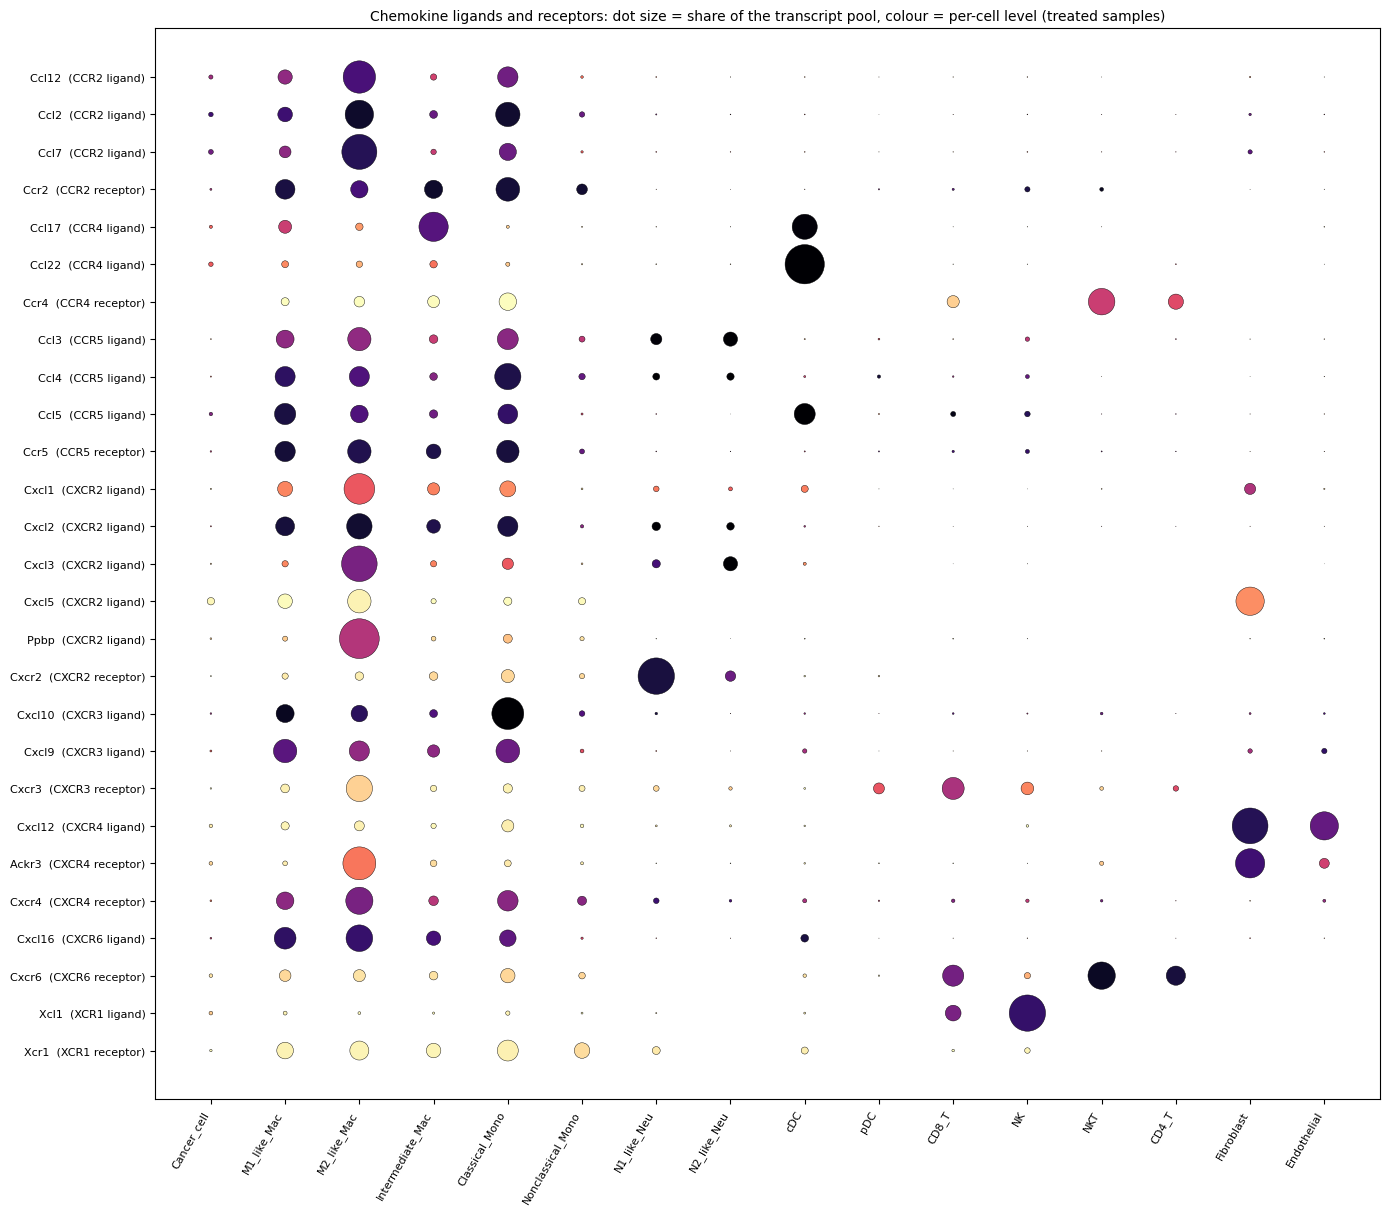

In [10]:
G_ = [g for g in LVL2 if g in set(src.group)]
genes_ = list(dict.fromkeys(SRC.gene))
fig, ax = plt.subplots(figsize=(14, 0.38*len(genes_) + 2))
for i, g in enumerate(genes_):
    d = src[src.gene == g].set_index("group").reindex(G_)
    ax.scatter(np.arange(len(G_)), np.full(len(G_), i), s=900*d.share.fillna(0).values, c=d.level.values,
               cmap="magma_r", vmin=0, vmax=np.nanpercentile(src.level, 98), edgecolor="k", lw=.3)
ax.set_xticks(range(len(G_))); ax.set_xticklabels(G_, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(genes_)))
AX_OF = dict(zip(SRC.gene, SRC.axis)); ROLE_OF = dict(zip(SRC.gene, SRC.role))
ax.set_yticklabels([f"{g}  ({AX_OF[g]} {ROLE_OF[g]})" for g in genes_], fontsize=8)
ax.invert_yaxis()
ax.set_title("Chemokine ligands and receptors: dot size = share of the transcript pool, colour = "
             "per-cell level (treated samples)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG/"01_chemokine_sources.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Summary

In [11]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print("\n[Q1 — top cell type per program, PER-CELL level, treated pooled | largest CONTRIBUTOR]")
for prog in HEAD:
    if prog not in H.columns: continue
    lv = H[prog].reindex([g for g in LVL2 if g in H.index]).dropna().sort_values(ascending=False)
    cs = cs_tr.loc[prog].dropna().sort_values(ascending=False) if prog in cs_tr.index else pd.Series(dtype=float)
    b = TOP[TOP.program == prog]
    stab = f"{(b.top1 == lv.index[0]).mean():.0%} of conditions, median boot {b.top1_boot.median():.0%}" if len(b) else ""
    print(f"    {prog:<26s} per-cell: {lv.index[0]} ({lv.iloc[0]:.1f}), {lv.index[1]} ({lv.iloc[1]:.1f})"
          f"  | contributor: {cs.index[0]} {100*cs.iloc[0]:.0f}%, {cs.index[1]} {100*cs.iloc[1]:.0f}%"
          f"  | #1 in {stab}")
print("\n[ambient — median intrinsic fraction in Cancer_cell (1 = own transcript)]")
print("   ", ", ".join(f"{g} {IF.loc[g, 'Cancer_cell']:.2f}" for g in GENES_AMB if g in IF.index))
print(f"    tumour cells free of ambient-marker reads: {100*tum.clean.mean():.0f}%")
for g in [g for g in ["H2-K1", "B2m", "Cd74", "H2-Ab1", "Cxcl9"] if f"{g}_clean" in CL]:
    print(f"    {g:<7s} clean/rest expression ratio {CL[f'{g}_clean'].mean()/max(CL[f'{g}_rest'].mean(), 1e-9):.2f}")
print("\n[chemokines — producers (contribution) and per-cell leaders, treated]")
print(SRC.to_string(index=False))
print(f"\n[decomposition] large source shifts (|d_share| >= 1): {len(big)}; driven by per-cell "
      f"expression {int((big.driver == 'per-cell expression').sum())}, by abundance "
      f"{int((big.driver == 'abundance').sum())}")
print(f"\n[files] {OUT}: q1_*.csv | [figures] 01_program_by_celltype.png, 01_chemokine_sources.png")
print("=" * 100)

SUMMARY — report these back

[Q1 — top cell type per program, PER-CELL level, treated pooled | largest CONTRIBUTOR]
    MHC_I_machinery            per-cell: NKT (8.5), cDC (8.3)  | contributor: M2_like_Mac 36%, Classical_Mono 25%  | #1 in 0% of conditions, median boot 96%
    MHC_II_core                per-cell: Intermediate_Mac (10.6), M1_like_Mac (10.3)  | contributor: M1_like_Mac 37%, Intermediate_Mac 30%  | #1 in 100% of conditions, median boot 100%
    IFNG_Hallmark              per-cell: Classical_Mono (6.8), M1_like_Mac (6.6)  | contributor: Classical_Mono 30%, M2_like_Mac 27%  | #1 in 80% of conditions, median boot 100%
    ISG_core                   per-cell: Classical_Mono (9.0), N1_like_Neu (8.7)  | contributor: Classical_Mono 40%, M2_like_Mac 25%  | #1 in 60% of conditions, median boot 86%
    cyto_effector              per-cell: NK (7.9), CD8_T (7.7)  | contributor: M1_like_Mac 22%, Classical_Mono 20%  | #1 in 60% of conditions, median boot 98%
    cyto_effector_noCcl5    